In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
ds = pd.read_csv("online_shoppers_intention.csv")

X = ds.drop(columns=["Revenue"])
y = ds["Revenue"]

In [43]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Encoded Classes:", label_encoder.classes_)

Encoded Classes: [False  True]


In [44]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

numeric_pipeline = Pipeline(steps = [
                        ("imputer", SimpleImputer(strategy='mean')),
                        ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps = [
                        ("imputer", SimpleImputer(strategy='most_frequent')),
                        ("encoder", OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

final_pipeline = Pipeline(steps = [
                        ("preprocessor", preprocessor),
                        ("classifier", RandomForestClassifier(n_estimators=100, criterion='entropy', random_state=0, n_jobs=-1))
                        # ("classifier", GradientBoostingClassifier(n_estimators=50))
                        # ("classifier", KNeighborsClassifier(n_neighbors=5, p=2, metric='minkowski'))
                        # ("classifier", GaussianNB())
])

In [45]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.25, random_state=0, stratify=y_encoded)

final_pipeline.fit(X_train, y_train)
y_pred = final_pipeline.predict(X_test)

Random Forest Accuracy: 90.46%

Classification Report:
              precision    recall  f1-score   support

       False       0.92      0.97      0.94      2606
        True       0.76      0.56      0.65       477

    accuracy                           0.90      3083
   macro avg       0.84      0.77      0.80      3083
weighted avg       0.90      0.90      0.90      3083



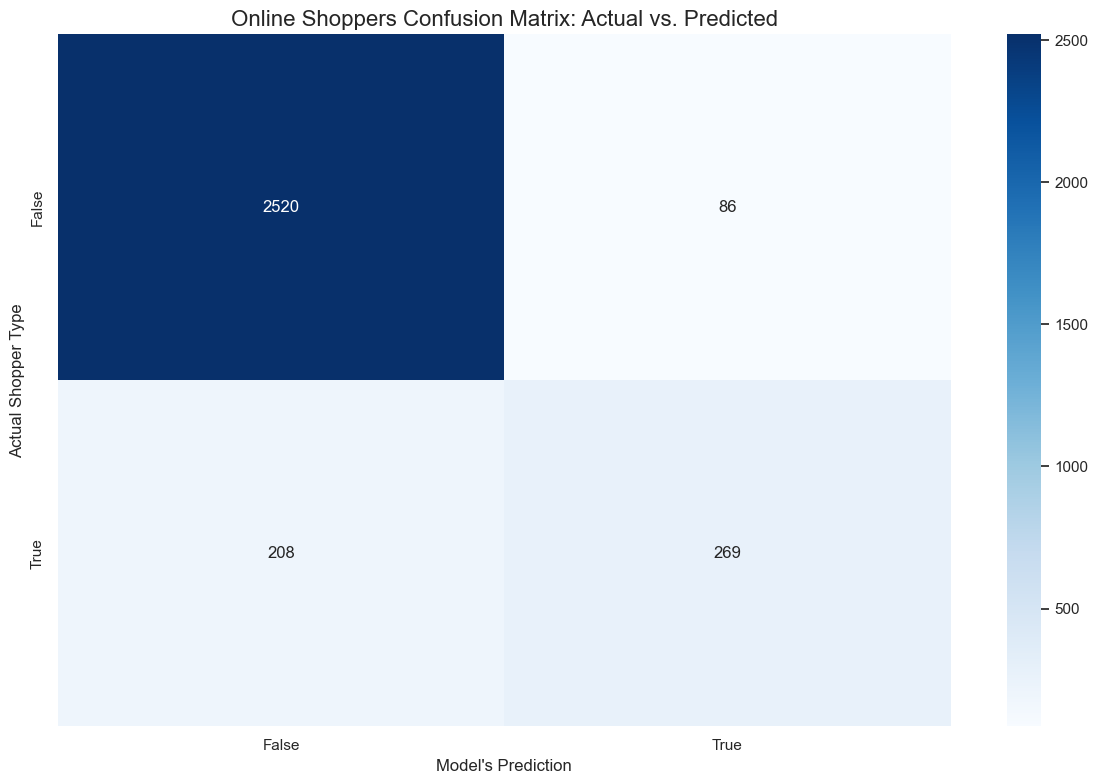

In [46]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

class_names = [str(cls) for cls in label_encoder.classes_]

cm = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
print(f"Random Forest Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

plt.figure(figsize=(12, 8))
sns.set_theme(style="white")

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, 
            yticklabels=class_names)

plt.title("Online Shoppers Confusion Matrix: Actual vs. Predicted", fontsize=16)
plt.ylabel("Actual Shopper Type", fontsize=12)
plt.xlabel("Model's Prediction", fontsize=12)

plt.xticks(rotation=0) 
plt.tight_layout()
plt.show()

Gradient Boosting Accuracy: 90.50%

Classification Report:
              precision    recall  f1-score   support

       False       0.93      0.96      0.94      2606
        True       0.74      0.60      0.66       477

    accuracy                           0.90      3083
   macro avg       0.83      0.78      0.80      3083
weighted avg       0.90      0.90      0.90      3083



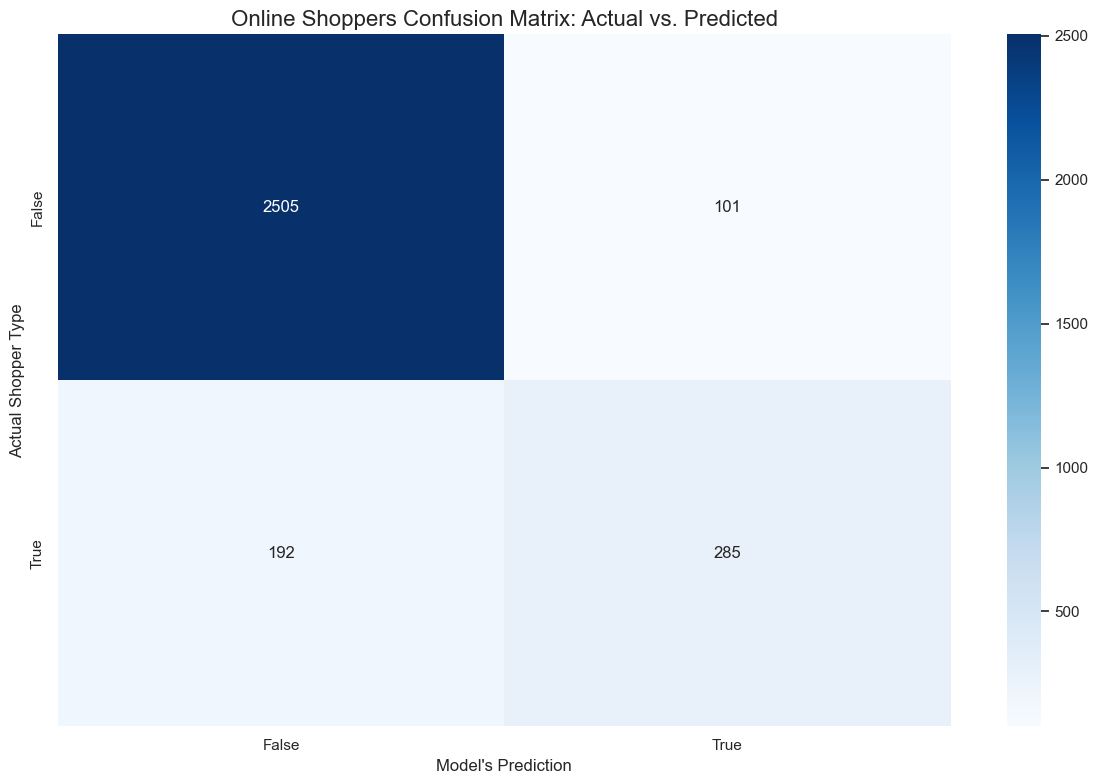

In [21]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

class_names = [str(cls) for cls in label_encoder.classes_]

cm = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
print(f"Gradient Boosting Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

plt.figure(figsize=(12, 8))
sns.set_theme(style="white")

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, 
            yticklabels=class_names)

plt.title("Online Shoppers Confusion Matrix: Actual vs. Predicted", fontsize=16)
plt.ylabel("Actual Shopper Type", fontsize=12)
plt.xlabel("Model's Prediction", fontsize=12)

plt.xticks(rotation=0) 
plt.tight_layout()
plt.show()

K-Nearest Neighbours Accuracy: 87.93%

Classification Report:
              precision    recall  f1-score   support

       False       0.90      0.96      0.93      2606
        True       0.68      0.42      0.52       477

    accuracy                           0.88      3083
   macro avg       0.79      0.69      0.72      3083
weighted avg       0.87      0.88      0.87      3083



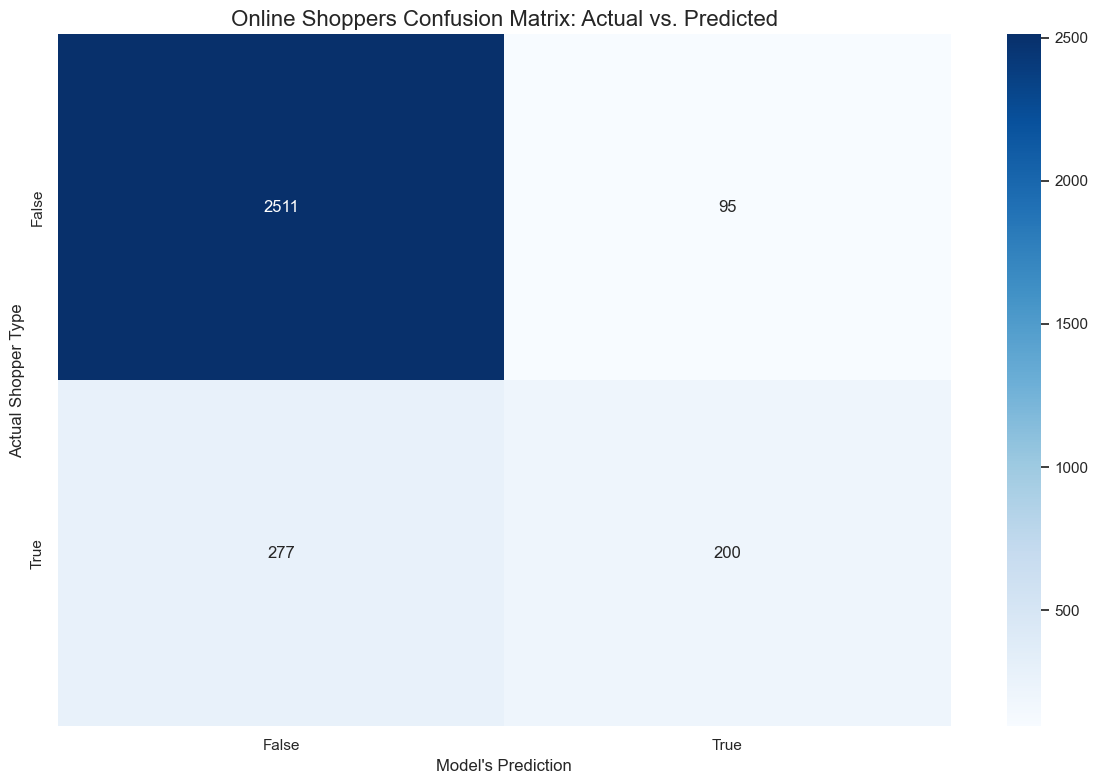

In [26]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

class_names = [str(cls) for cls in label_encoder.classes_]

cm = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
print(f"K-Nearest Neighbours Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

plt.figure(figsize=(12, 8))
sns.set_theme(style="white")

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, 
            yticklabels=class_names)

plt.title("Online Shoppers Confusion Matrix: Actual vs. Predicted", fontsize=16)
plt.ylabel("Actual Shopper Type", fontsize=12)
plt.xlabel("Model's Prediction", fontsize=12)

plt.xticks(rotation=0) 
plt.tight_layout()
plt.show()

Naive Bayes Accuracy: 69.54%

Classification Report:
              precision    recall  f1-score   support

       False       0.95      0.68      0.79      2606
        True       0.31      0.78      0.44       477

    accuracy                           0.70      3083
   macro avg       0.63      0.73      0.62      3083
weighted avg       0.85      0.70      0.74      3083



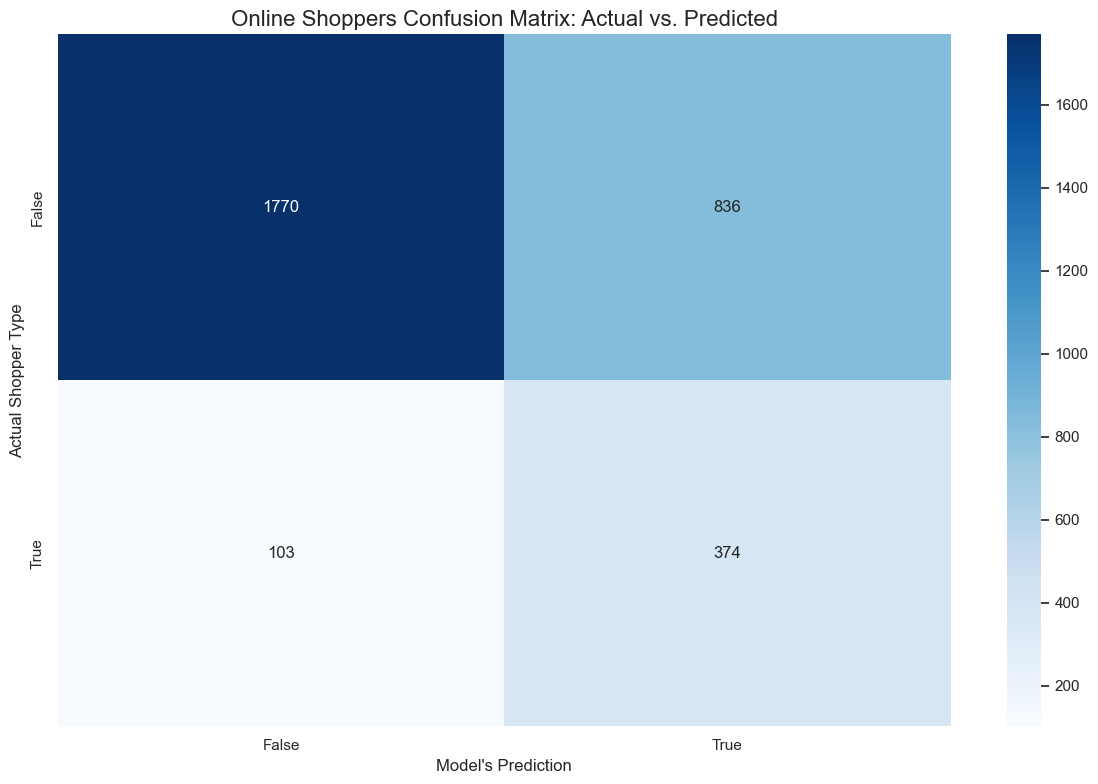

In [31]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

class_names = [str(cls) for cls in label_encoder.classes_]

cm = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
print(f"Naive Bayes Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

plt.figure(figsize=(12, 8))
sns.set_theme(style="white")

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, 
            yticklabels=class_names)

plt.title("Online Shoppers Confusion Matrix: Actual vs. Predicted", fontsize=16)
plt.ylabel("Actual Shopper Type", fontsize=12)
plt.xlabel("Model's Prediction", fontsize=12)

plt.xticks(rotation=0) 
plt.tight_layout()
plt.show()